In [5]:
from matplotlib import pyplot as plt
import fastf1
import fastf1.plotting
import pandas as pd
import numpy as np
from statistics import mean
import seaborn as sns
from pathlib import Path
import os

import statsmodels.formula.api as sm
from sklearn import svm
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import scale
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder

In [6]:
BASE_DIR = Path.cwd()
data_dir = BASE_DIR / "f1 data raw"

data_dir.mkdir(parents=True, exist_ok=True)

In [3]:
#function to gather the data
def driver_per_race(session):
    total_table = pd.DataFrame(columns = ["Driver", "Team", "Result", "Start Pos", "Finish Pos", "Max Speed",
                                          "Avg Speed","DRS active", "Total Laps", "Soft Percent", "Medium Percent",
                                          "Hard Percent", "Intermediate Percent", "Wet Percent", 'total_pit_time'])
    #for time delta
    time_count = pd.Timedelta(0).total_seconds()
    #iterates through each driver for that race
    for driver in session.drivers:
        #breaks for when race is missing/not happened yet
        try:
            code = session.get_driver(driver).Abbreviation
            team = session.get_driver(driver).TeamName
            tele = session.laps.pick_driver(driver).get_telemetry()
            tele = tele[tele['Status'].str.contains("OnTrack")]

            compounds = {'SOFT': 0, 'MEDIUM': 0, 'HARD': 0, 'INTERMEDIATE': 0, 'WET': 0}
            laps = len(session.laps.pick_driver(driver))

            time_count = time_count + session.get_driver(driver)['Time'].total_seconds()

            sp_max = tele["Speed"].max()
            sp_avg = tele["Speed"].mean()
            drs_prop = len(tele[tele["DRS"] > 8]) / len(tele["DRS"]) * 100
            start = session.get_driver(driver)['GridPosition']
            end = session.get_driver(driver)['Position']
            storage = [code, team, time_count, start, end, sp_max, sp_avg,drs_prop, laps]

            #tire data
            for tire in session.laps.pick_driver(driver)["Compound"]:
                compounds[tire] += 1

            storage = storage + [compounds['SOFT']/laps, compounds['MEDIUM']/laps,
                                 compounds['HARD']/laps, compounds['INTERMEDIATE']/laps, compounds['WET']/laps]
            #pit times
            pit_in = session.laps.pick_driver(driver)['PitInTime'].reset_index(drop=True)
            pit_out = session.laps.pick_driver(driver)['PitOutTime'].reset_index(drop=True)

            temp_array = []
            for number in range(len(pit_in)-1):
                pit_time = pit_out[number + 1] - pit_in[number]
                temp_array.append(pit_time)

            filtered_array = [x for x in temp_array if x is not pd.NaT]

            total_pit_time = sum(filtered_array, pd.Timedelta(0)).total_seconds()
            storage = storage + [total_pit_time]
            total_table = pd.concat([total_table, pd.DataFrame([storage], columns = total_table.columns)], ignore_index = True)
        except Exception as e:
            pass

    max_stints = session.laps.groupby('Driver').agg(Max_Stint=('Stint', 'max')).reset_index()
    total_table = pd.merge(total_table, max_stints, on='Driver')
    return(total_table)

In [4]:
#function to create dicitonary of races for each championship year
def year_data(year):
    rounds = {}
    try:
        for race in range(max(fastf1.get_event_schedule(year).RoundNumber)):
            session = fastf1.get_session(year, race + 1, 'R')
            session.load()
            print('loaded')
            event_data = driver_per_race(session)
            rounds[str(session.event.EventName)] = event_data
    except Exception as e:
        return(rounds)

    return(rounds)

Note: This below code was used to retrieve all the  data from the FastF1 API. Rerunning this chunk is not advised. The API will try to load all the telemetry data from the requested data, is extremely large. This will likely result in an out of memory issue and cause the kernel to shut down. When my team ran it for the project, we did so on Google Colab, the process took almost an hour. All the necessary data from it has been stored in the 'f1 data raw' folder. Please make sure to download that folder if running locally.

In [ ]:
############################
######## DO NOT RUN ########
############################
drivers2022 = year_data(2022)
drivers2023 = year_data(2023)
drivers2024 = year_data(2024)

In [ ]:
############################
######## DO NOT RUN ########
############################

#makes csvs for each race and a combined data

#for combined data
driver_data_list = []

year_list = [2022, 2023, 2024]
for i in year_list:
    d_list = f"drivers{i}"
    for item in globals()[d_list]:
        ref = globals()[d_list][item]
        driver_data_list.append(ref)
        csv_name = f"{item} {i}.csv"
        csv_path = data_dir / csv_name
        ref.to_csv(csv_path, index=False)

total_results = pd.concat(driver_data_list, ignore_index = True)
csv_name = "total drivers data.csv"
csv_path = BASE_DIR / csv_name
total_results.to_csv(csv_path, index=False)

In [7]:
#data retrieval and normalization
folder_path = data_dir

csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
csv_list = []

for csv_file in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    
    df = pd.read_csv(file_path)
    df = df.dropna(subset=['Result'])
    df['Max Speed'] = (df['Max Speed'] - df['Max Speed'].median()) / max(abs((df['Max Speed'] - df['Max Speed'].median())))
    df['Avg Speed'] = (df['Avg Speed'] - df['Avg Speed'].median()) / max(abs((df['Avg Speed'] - df['Avg Speed'].median())))
    df['total_pit_time'] = (df['total_pit_time'] - df['total_pit_time'].median()) / max(abs((df['total_pit_time'] - df['total_pit_time'].median())))
    csv_list.append(df)
    
    master_driver = pd.concat(csv_list)

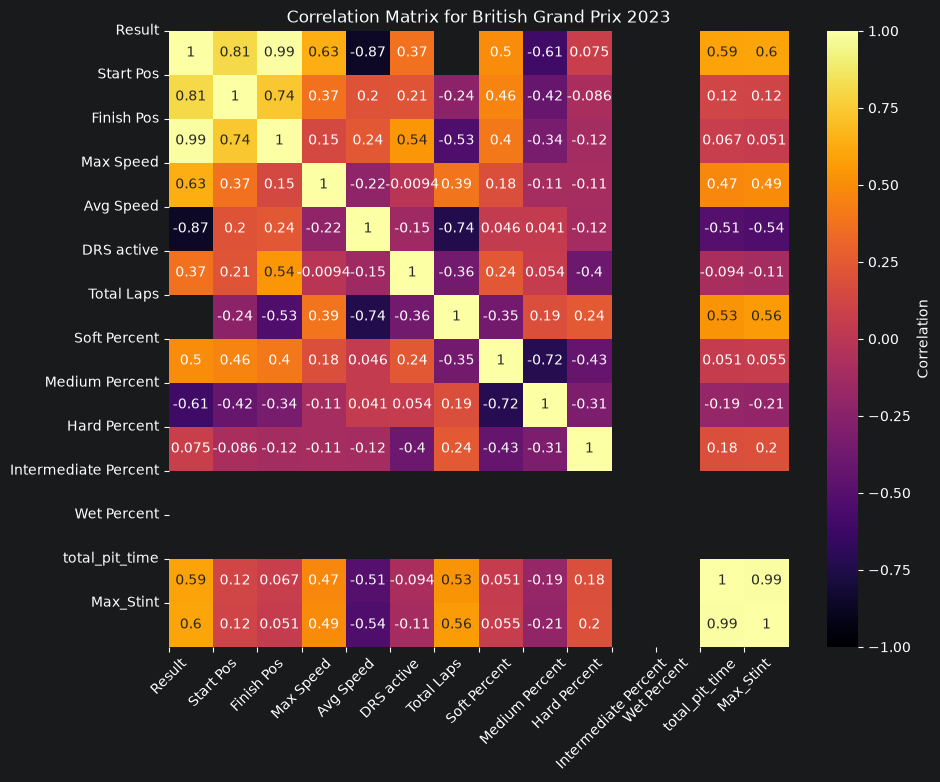

In [8]:
#Read in British Grand Prix csv using pandas
BritGP2023 = pd.read_csv("f1 data raw/British Grand Prix 2023.csv")

#Creating Correlation Matrix
corr_matrix = BritGP2023.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

heatmap = sns.heatmap(corr_matrix, cmap='inferno', annot=True, vmin=-1, vmax=1)

# Create colorbar directly from the heatmap object
colorbar = heatmap.collections[0].colorbar
colorbar.set_label('Correlation')

plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=45)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)

plt.title('Correlation Matrix for British Grand Prix 2023')
plt.show()

In [9]:
#Loop to fix variable names so they pull into the ols function properly
for column in BritGP2023.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        BritGP2023.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based off the variables with the strongest variables to predict Result time.
Result_Time_ols = sm.ols(formula="Result ~ Start_Pos + Avg_Speed", data=BritGP2023).fit()
Result_Time_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Result   R-squared:                       0.781
Model:                            OLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     24.96
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           2.42e-05
Time:                        01:04:33   Log-Likelihood:                -49.999
No. Observations:                  17   AIC:                             106.0
Df Residuals:                      14   BIC:                             108.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   3458.0036   1199.476      2.883      0.012     885.383    6030.624
Start_Pos      0.5101      0.360      1.416      0.179      -0.262       1.283
Avg_Speed    -16.2734      5.653     -2.879      0.012     -28.398      -4.149
==============================================================================
Omnibus:                        4.333   Durbin-Watson:                   1.691
Prob(Omnibus):                  0.115   Jarque-Bera (JB):                2.197
Skew:                          -0.828   Prob(JB):                        0.333
Kurtosis:                       3.599   Cond. No.                     2.08e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.08e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [10]:
#Loop to fix variable names so they pull into the ols function properly
for column in BritGP2023.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        BritGP2023.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based for Result ~ Average Speed
Result_Time_ols = sm.ols(formula="Result ~ Avg_Speed", data=BritGP2023).fit()
Result_Time_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Result   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     44.91
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           7.09e-06
Time:                        01:04:41   Log-Likelihood:                -51.137
No. Observations:                  17   AIC:                             106.3
Df Residuals:                      15   BIC:                             107.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4840.8362    719.584      6.727      0.000    3307.080    6374.593
Avg_Speed    -22.7825      3.400     -6.702      0.000     -30.028     -15.537
==============================================================================
Omnibus:                        1.802   Durbin-Watson:                   1.374
Prob(Omnibus):                  0.406   Jarque-Bera (JB):                1.392
Skew:                          -0.655   Prob(JB):                        0.499
Kurtosis:                       2.501   Cond. No.                     1.20e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.2e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

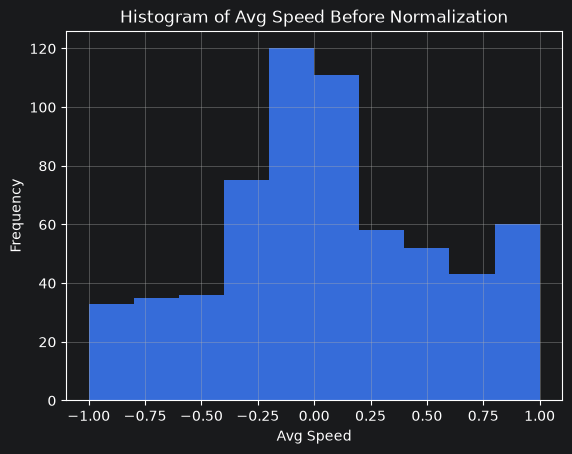

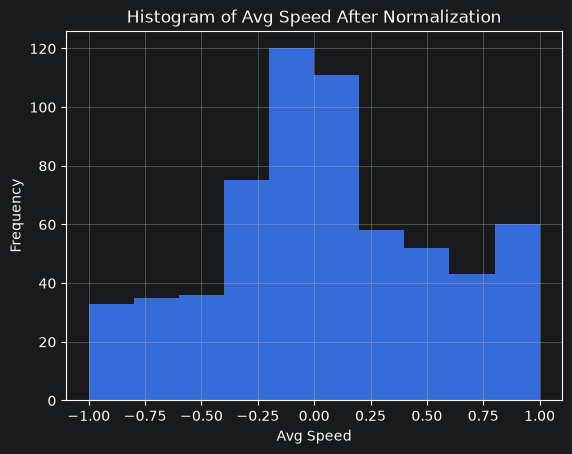

In [11]:
#Creating a histogram for Average Speed before normalizing the variable.
master_driver['Avg Speed'].hist()

# Add labels and title
plt.xlabel('Avg Speed')
plt.ylabel('Frequency')
plt.title('Histogram of Avg Speed Before Normalization')

# Show the plot
plt.show()


#Creating a histogram for Average Speed after normalizing the variable.
master_driver['Avg Speed'].hist()

# Add labels and title
plt.xlabel('Avg Speed')
plt.ylabel('Frequency')
plt.title('Histogram of Avg Speed After Normalization')

# Show the plot
plt.show()

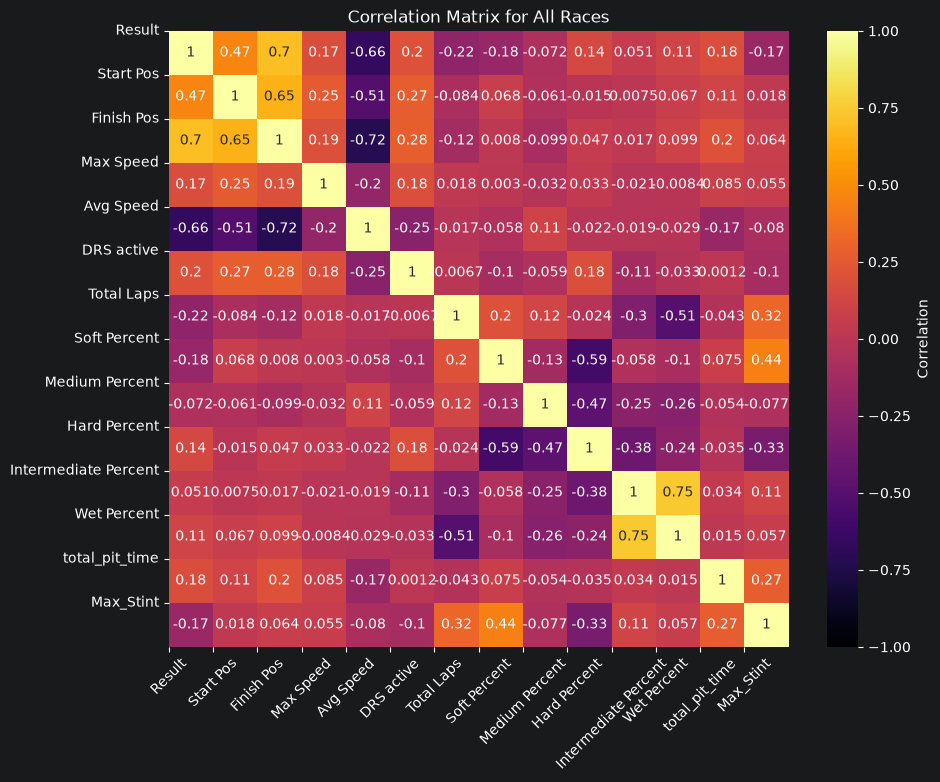

In [12]:
#Creating Correlation Matrix
corr_matrix = master_driver.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

heatmap = sns.heatmap(corr_matrix, cmap='inferno', annot=True, vmin=-1, vmax=1)

# Create colorbar directly from the heatmap object
colorbar = heatmap.collections[0].colorbar
colorbar.set_label('Correlation')

plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=45)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)

plt.title('Correlation Matrix for All Races')
plt.show()

In [13]:
#Regression model for Result Time ~ Starting Position + Average Speed

#Loop to fix variable names so they pull into the ols function properly
for column in master_driver.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        master_driver.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based off the variables with the strongest variables to predict Result time.
Result_Time_ols = sm.ols(formula="Result ~ Start_Pos + Avg_Speed", data=master_driver).fit()
Result_Time_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Result   R-squared:                       0.461
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     265.4
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           5.50e-84
Time:                        01:04:55   Log-Likelihood:                -2813.2
No. Observations:                 623   AIC:                             5632.
Df Residuals:                     620   BIC:                             5646.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     35.8463      1.887     18.998      0.000      32.141      39.552
Start_Pos      0.9577      0.187      5.115      0.000       0.590       1.325
Avg_Speed    -34.2265      2.048    -16.714      0.000     -38.248     -30.205
==============================================================================
Omnibus:                        1.727   Durbin-Watson:                   0.482
Prob(Omnibus):                  0.422   Jarque-Bera (JB):                1.568
Skew:                          -0.073   Prob(JB):                        0.457
Kurtosis:                       3.198   Cond. No.                         27.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [14]:
#Regression model for Finishing Position ~ Starting Position + Average Speed

#Loop to fix variable names so they pull into the ols function properly
for column in master_driver.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        master_driver.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based off the variables with the strongest variables to predict Result time.
Result_Time_ols = sm.ols(formula="Finish_Pos ~ Start_Pos + Avg_Speed", data=master_driver).fit()
Result_Time_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             Finish_Pos   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     536.2
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          6.38e-136
Time:                        01:05:05   Log-Likelihood:                -1497.8
No. Observations:                 623   AIC:                             3002.
Df Residuals:                     620   BIC:                             3015.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.0243      0.228     21.994      0.000       4.576       5.473
Start_Pos      0.3088      0.023     13.624      0.000       0.264       0.353
Avg_Speed     -4.6283      0.248    -18.669      0.000      -5.115      -4.141
==============================================================================
Omnibus:                       38.771   Durbin-Watson:                   1.012
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               52.812
Skew:                           0.517   Prob(JB):                     3.40e-12
Kurtosis:                       3.982   Cond. No.                         27.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [15]:
#alternate file retrieval for more information
folder_path = 'f1 data raw/'

csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
csv_list = []

for csv_file in csv_files:
    file_path = os.path.join(folder_path, csv_file)

    track = csv_file[:-9]
    df = pd.read_csv(file_path)
    df = df.dropna(subset=['Result'])
    df['Track'] = track
    csv_list.append(df)

    # vectorizes Driver and Track data
    master_driver = pd.concat(csv_list, ignore_index = True)

In [16]:
#vectorizes Driver and Track information
ohe = OneHotEncoder()
ohe_array = ohe.fit_transform(master_driver[['Driver', 'Track']]).toarray()
column_names = ohe.get_feature_names_out(['Driver', 'Track'])
ohe_df = pd.DataFrame(ohe_array, columns= column_names)

In [17]:
#fitting for models
X = pd.concat([master_driver.drop(columns=['Driver','Track', 'Team', 'Result', 'Finish Pos']), ohe_df], axis = 1)
y = master_driver['Finish Pos']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state = 2)

scaler = StandardScaler()
scaler.fit(X_train)

x_train = scaler.transform(X_train)
x_test = scaler.transform(X_test)

In [18]:
#linear regression model
lin_reg = LinearRegression()
print(lin_reg.get_params())

lin_reg.fit(x_train, y_train)
print(lin_reg.intercept_)
print(lin_reg.coef_)

print(lin_reg.score(x_test,y_test))

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}
7.588353413654619
[ 0.94371567  0.7137072  -1.8262292   0.49160065 -1.26681085 -0.26769226
 -0.05812804  0.20441437 -0.20708388  1.47882409 -3.20922051  1.40052683
  0.57736835 -0.20306713 -0.05811959  0.39814619  0.3240904   0.43922881
 -0.50399148  0.74711856  0.64375815  0.07744744 -0.54766791  0.53717113
  0.39564236 -0.11028426  0.04719452 -0.93107836  0.02342575  0.44983968
 -0.43267537 -0.49602676  0.6137688   0.17718021  0.471435   -1.16201388
  0.23186379  0.57456576  0.08178273 -0.15668511  0.05058609 -0.1643709
 -0.22339695 -0.16352479  0.38399423  0.10983208  0.13235379  0.09392935
  0.02937904  0.13752267  0.08940207 -0.14673844 -0.18910897  0.08976094
  0.14806564  0.15175415 -0.19971492  0.1034923   0.1355798  -0.11412126
  0.03083119 -0.32571489]
0.762711905435854


In [19]:
# MLP NN
array_list = []
for m in range(10):
    i_scores = []
    for i in range(10):
        f_scores = []
        for f in range(5):
            mlp_reg = MLPRegressor(hidden_layer_sizes=(2*m + 30, 2*i + 20),verbose=0, activation='relu', solver='adam', max_iter=5000)
            mlp_reg.fit(x_train, y_train)
            f_scores.append(mlp_reg.score(x_test,y_test))
        i_scores.append(mean(f_scores))
    array_list.append(i_scores)
nn_scores = pd.DataFrame(array_list)

<Axes: >

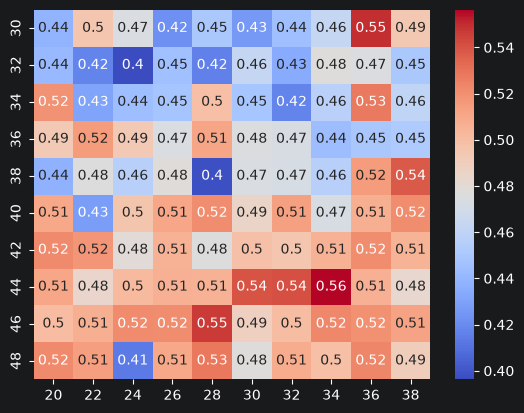

In [20]:
nn_scores.index = ['30', '32', '34', '36', '38', '40', '42', '44', '46', '48']
nn_scores.columns = ['20', '22', '24', '26', '28', '30', '32', '34', '36', '38']
sns.heatmap(nn_scores, cmap = 'coolwarm', annot=True)

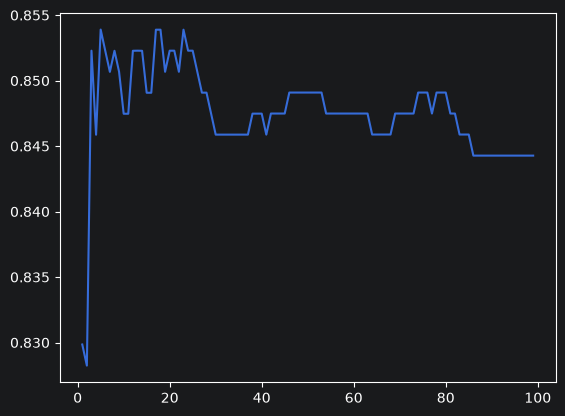

The max accuracy is 0.8538957017217887


In [21]:
# SVM

# Create binary classifier
master_driver['Finish Pos'] = master_driver['Finish Pos'] <= 3
y = master_driver['Finish Pos']    #labels

# iterate through c-values to find the optimal one based on cross-validation score
Cs = range(1,100)
Accuracies = np.zeros(len(Cs))
for i,C in enumerate(Cs):
    svm_classifier = svm.SVC(kernel='rbf', C = C,gamma='auto')
    scores = cross_val_score(estimator = svm_classifier, X = scale(X), y = y, cv = 3, scoring='accuracy')
    Accuracies[i]  = scores.mean()

# plot the accuacies as a function of c-value:
plt.plot(Cs[0:100],Accuracies[0:100])
plt.show()

# print the maximum accuracy value
print("The max accuracy is " + str(max(Accuracies)))